# Roshni: results walkthrough (runs on a CPU in a few minutes)

This notebook checks the finished run using only the files in this repository: the per-photo predictions, the trained model (`results/model_best.pt`), the photo-quality check (`results/quality_gate.pkl`) and the browser model (`web/model.onnx`). The training itself is in `Roshni_DR_Screening.ipynb` (needs a GPU, run on Kaggle).

1. Recompute every headline number from the per-photo predictions, independently of the code that wrote the README
2. The photo-quality check: false all-clears with and without it
3. The stress test on deliberately worse photos
4. Run the trained model live on the five demo photos, with heat maps and the clinic note
5. Check that the browser model gives the same numbers as PyTorch
6. Optional: re-score all 400 external validation photos and compare with the saved run

No APTOS photo is shown here: the competition's rules do not allow sharing its images. The photos shown are from DeepDRiD (CC BY-SA 4.0).

> This project is a prototype and is not medical advice.

## 0. Setup
In Colab or Kaggle, this cell downloads the repository first.

In [1]:
import os, sys, json, pickle, time, subprocess
if not os.path.exists('results/results.json'):
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/MACVXACE/roshni.git'], check=True)
    os.chdir('roshni')
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, torch, sklearn, PIL
import matplotlib.pyplot as plt
from IPython.display import Image as Show, HTML, display
from sklearn.metrics import roc_auc_score, cohen_kappa_score
import drscreen as ds
pd.set_option('display.width', 160)
res = json.load(open('results/results.json'))
fr = res['frozen']; THR, PT, SIZE = fr['ref_threshold'], fr['poor_threshold'], fr['size']
print('torch', torch.__version__, '| scikit-learn', sklearn.__version__, '| Pillow', PIL.__version__)
print(f"Frozen before testing: model {fr['arch']} at {SIZE} px, referral threshold {THR:.3f} "
      f"(set for {fr['target_sensitivity']:.0%} sensitivity on validation), quality cut-off {PT}")

torch 2.15.0+cu132 | scikit-learn 1.9.1 | Pillow 12.3.0
Frozen before testing: model efficientnet_b0 at 384 px, referral threshold 0.614 (set for 90% sensitivity on validation), quality cut-off 0.5


### Training history
The model kept is the epoch with the best validation AUC (validation photos only; the test set was not used).

In [2]:
h = pd.read_csv('results/training_history.csv')
print(h.round(4).to_string(index=False))
print('Best validation AUC at epoch', int(h.loc[h.val_auc.idxmax(), 'epoch']))

 epoch  train_loss  val_auc  seconds
     1      1.3350   0.9506  25.4197
     2      0.7836   0.9825  25.3876
     3      0.6715   0.9865  25.2805
     4      0.6130   0.9833  25.2007
     5      0.5837   0.9874  25.3729
     6      0.5502   0.9835  25.2766
     7      0.4949   0.9808  25.2821
     8      0.4818   0.9841  25.4394
     9      0.4297   0.9771  25.3794
    10      0.4127   0.9757  25.3821
    11      0.3884   0.9786  25.3117
    12      0.3799   0.9788  25.3551
Best validation AUC at epoch 5


## 1. Headline numbers, recomputed from the per-photo predictions
`results/aptos_test_predictions.csv` has one row per held-out APTOS test photo, and `results/deepdrid_predictions.csv` one row per external DeepDRiD photo. A photo is **referable** at grade 2 or worse; Roshni says REFER when the referable score is at or above the frozen threshold.

In [3]:
ap = pd.read_csv('results/aptos_test_predictions.csv')
dd = pd.read_csv('results/deepdrid_predictions.csv'); dd = dd[dd.grade <= 4]
def metrics(name, y, p):
    y = np.asarray(y, bool); pred = np.asarray(p) >= THR
    return dict(set=name, photos=len(y), referable=int(y.sum()), AUC=round(roc_auc_score(y, p), 3),
                sensitivity=f'{(pred & y).sum() / y.sum():.1%}', specificity=f'{(~pred & ~y).sum() / (~y).sum():.1%}',
                missed=int((~pred & y).sum()), false_alarms=int((pred & ~y).sum()))
rows = [metrics('APTOS test (India, held out)', ap.grade >= 2, ap.p_referable),
        metrics('DeepDRiD (China, external)', dd.grade >= 2, dd.p_referable),
        metrics('  external, good photos', dd[dd.poor_quality == 0].grade >= 2, dd[dd.poor_quality == 0].p_referable),
        metrics('  external, poor photos', dd[dd.poor_quality == 1].grade >= 2, dd[dd.poor_quality == 1].p_referable)]
display(pd.DataFrame(rows))
print('Saved in results.json: APTOS AUC', round(res['results']['fine_tuned']['AUC'], 3),
      '| external AUC', round(res['results']['external_all']['AUC'], 3))

,set,photos,referable,AUC,sensitivity,specificity,missed,false_alarms
0,"APTOS test (India, held out)",352,152,0.978,84.2%,94.0%,24,12
1,"DeepDRiD (China, external)",1600,700,0.911,56.1%,97.2%,307,25
2,"external, good photos",758,356,0.936,54.5%,99.3%,162,3
3,"external, poor photos",842,344,0.891,57.8%,95.6%,145,22


Saved in results.json: APTOS AUC 0.978 | external AUC 0.911


Baselines on the same APTOS test photos, thresholded the same way:


,model,n,referable,AUC,sensitivity,specificity,PPV,NPV,missed_FN,false_alarms_FP,referred_share
0,Colour histogram + logistic regression,352,152,0.848,0.842,0.720,0.696,0.857,24,56,0.523
1,"Pretrained features, not fine-tuned + logistic...",352,152,0.968,0.836,0.935,0.907,0.882,25,13,0.398
2,Fine-tuned efficientnet_b0,352,152,0.978,0.842,0.940,0.914,0.887,24,12,0.398
3,"Fine-tuned, external DeepDRiD (China)",1600,700,0.911,0.561,0.972,0.940,0.740,307,25,0.261
4,"External, good-quality photos",758,356,0.936,0.545,0.993,0.985,0.711,162,3,0.260
5,"External, poor-quality photos",842,344,0.891,0.578,0.956,0.900,0.767,145,22,0.262


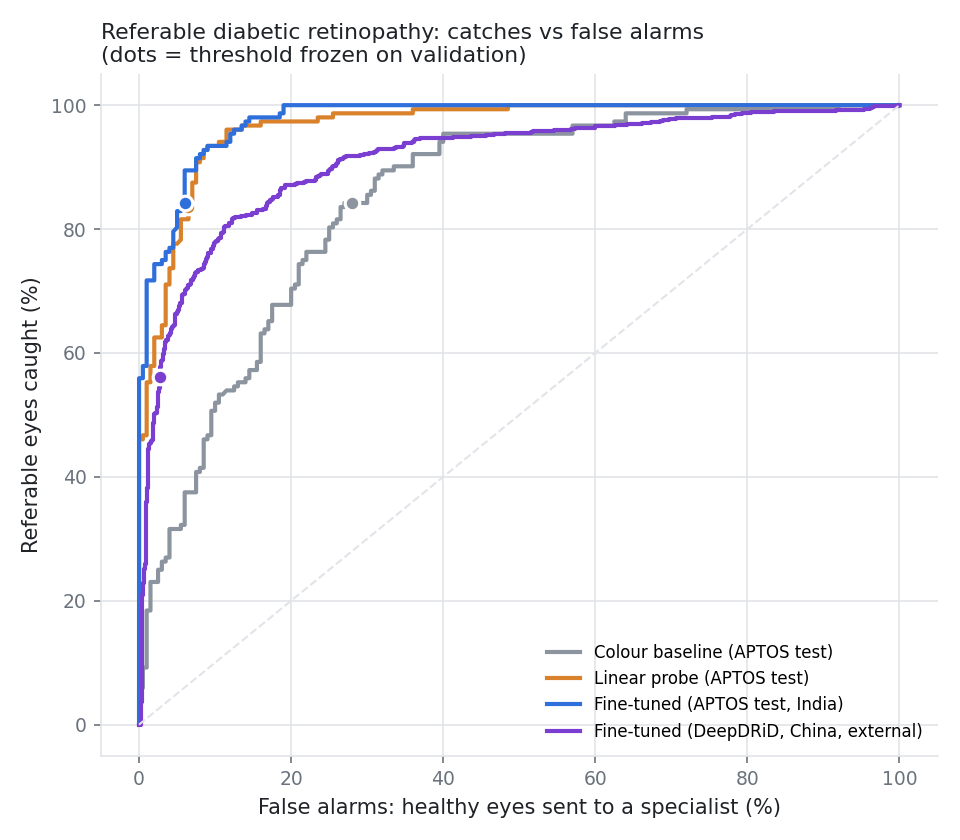

In [4]:
print('Baselines on the same APTOS test photos, thresholded the same way:')
display(pd.read_csv('results/summary.csv').round(3))
display(Show('results/roc.png', width=520))

### By grade (APTOS test)

In [5]:
by = pd.DataFrame({'grade': [f'{g} {ds.GRADES[g]}' for g in range(5)],
                   'photos': [int((ap.grade == g).sum()) for g in range(5)],
                   'sent to specialist': [int(((ap.grade == g) & (ap.p_referable >= THR)).sum()) for g in range(5)]})
display(by)
print('Five-grade agreement (quadratic weighted kappa):', round(cohen_kappa_score(ap.grade, ap.pred_grade, weights='quadratic'), 3))
print('Confusion matrix (rows: expert grade, columns: predicted grade):')
print(pd.crosstab(ap.grade, ap.pred_grade))

,grade,photos,sent to specialist
0,0 No DR,153,0
1,1 Mild,47,12
2,2 Moderate,102,82
3,3 Severe,17,17
4,4 Proliferative,33,29


Five-grade agreement (quadratic weighted kappa): 0.889
Confusion matrix (rows: expert grade, columns: predicted grade):
pred_grade    0   1   2  3   4
grade                         
0           153   0   0  0   0
1             0  32  15  0   0
2             2  11  87  2   0
3             0   0  10  3   4
4             0   3  11  1  18


### External results by hospital source
DeepDRiD records no age or sex, so we compare by source and photo quality.

In [6]:
src = dd.assign(ref=dd.grade >= 2, pred=dd.p_referable >= THR).groupby('Source').apply(
    lambda g: pd.Series({'photos': len(g), 'sensitivity': f'{(g.pred & g.ref).sum() / g.ref.sum():.1%}',
                         'specificity': f'{(~g.pred & ~g.ref).sum() / (~g.ref).sum():.1%}'}))
display(src)
print('External AUC 95% interval, resampling whole patients:', np.round(res['results']['external_all']['AUC_CI_by_patient'], 3))

,photos,sensitivity,specificity
Source,,,
Nation,56,54.2%,93.8%
Nicheng,1508,55.8%,97.4%
Shanghai,36,65.4%,90.0%


External AUC 95% interval, resampling whole patients: [0.89 0.93]


### Leakage check
Near-duplicate photos (image hashing) were grouped, and each group kept on one side of the split.

In [7]:
sp = pd.read_csv('results/aptos_split.csv')
print(sp.split.value_counts().to_string())
print('Largest number of splits any near-duplicate group appears in:', sp.groupby('dup_group').split.nunique().max(), '(1 = no leakage)')
print('Test photos in the split file = test photos scored:', set(sp[sp.split == 'test'].id_code) == set(ap.id_code))

split
train    2886
val       424
test      352
Largest number of splits any near-duplicate group appears in: 1 (1 = no leakage)
Test photos in the split file = test photos scored: True


## 2. Our own question: does the photo-quality check stop false all-clears?
The 400 DeepDRiD **validation** photos were never used to train either the grading model or the quality check. The rule: REFER if the referable score is at or above the threshold; otherwise RETAKE if the quality check says poor; otherwise RESCREEN in 12 months (the all-clear).

In [8]:
v = pd.read_csv('results/deepdrid_predictions.csv'); v = v[(v.part == 'validation') & (v.grade <= 4)]
def run(gate):
    d = np.where(v.p_referable >= THR, 'REFER', np.where(gate & (v.p_poor >= PT), 'RETAKE', 'RESCREEN'))
    ref, sev = (v.grade >= 2).values, (v.grade >= 3).values
    return {'REFER': (d == 'REFER').sum(), 'RETAKE': (d == 'RETAKE').sum(), 'RESCREEN (all-clear)': (d == 'RESCREEN').sum(),
            'referable eyes given an all-clear': ((d == 'RESCREEN') & ref).sum(),
            'grade 3-4 eyes given an all-clear': ((d == 'RESCREEN') & sev).sum()}
display(pd.DataFrame({'without quality check': run(False), 'with quality check': run(True)}))
print('Quality check finds poor photos with AUC', round(roc_auc_score(v.poor_quality, v.p_poor), 3))

,without quality check,with quality check
REFER,104,104
RETAKE,0,154
RESCREEN (all-clear),296,142
referable eyes given an all-clear,81,46
grade 3-4 eyes given an all-clear,13,4


Quality check finds poor photos with AUC 0.708


## 3. Stress test: photos made worse in four fixed ways, at two strengths
Planned before any result: blur, lower resolution, under-exposure and messaging-app compression. Nothing was re-tuned.

,photos,change,strength,sensitivity,specificity,retake_share,referable_all_clear_without_check,referable_all_clear_with_check
0,APTOS test,clean,none,0.842,0.940,0.287,24,15
1,APTOS test,blur,mild,0.671,0.975,0.233,50,36
2,APTOS test,blur,strong,0.349,0.990,0.634,99,38
3,APTOS test,low_resolution,mild,0.724,0.965,0.188,42,33
4,APTOS test,low_resolution,strong,0.592,0.975,0.588,62,25
5,APTOS test,underexposed,mild,0.882,0.940,0.293,18,9
6,APTOS test,underexposed,strong,0.862,0.920,0.352,21,7
7,APTOS test,compressed,mild,0.993,0.665,0.276,1,1
8,APTOS test,compressed,strong,0.993,0.255,0.122,1,0
9,DeepDRiD validation,clean,none,0.550,0.977,0.385,81,46


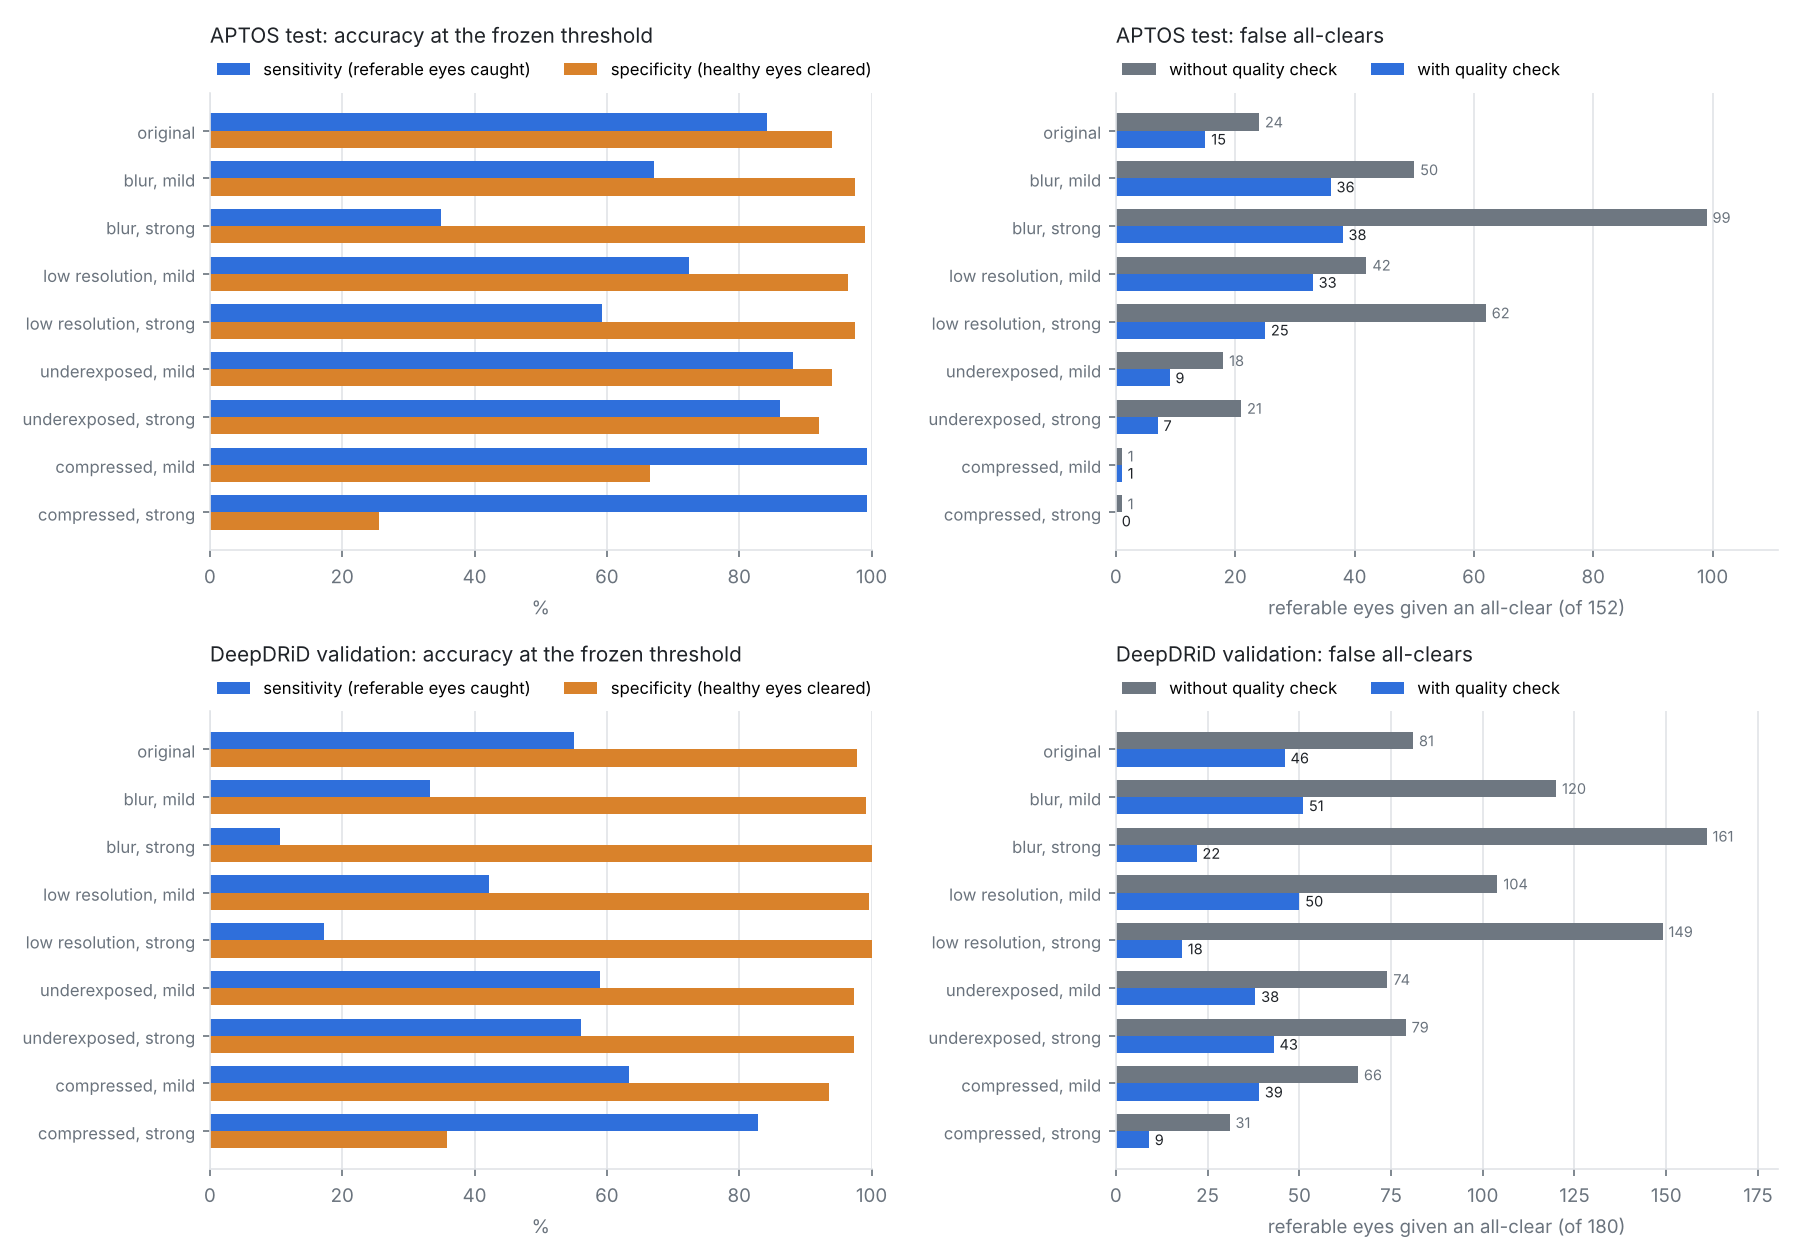

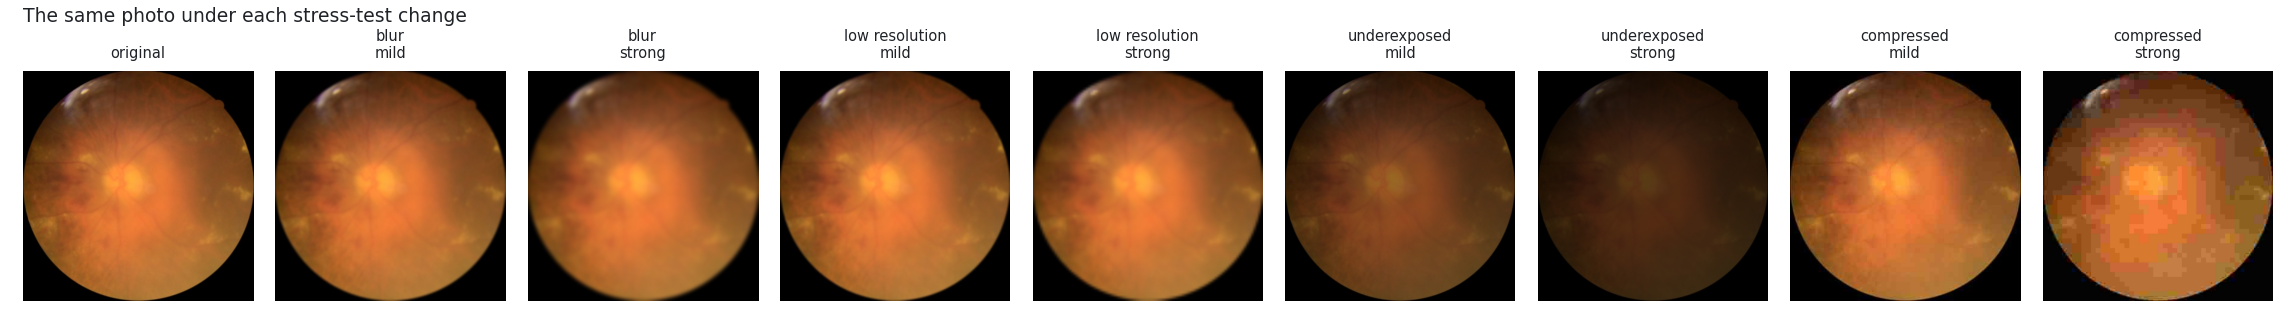

In [9]:
st = pd.read_csv('results/stress_test.csv')
cols = ['photos', 'change', 'strength', 'sensitivity', 'specificity', 'retake_share',
        'referable_all_clear_without_check', 'referable_all_clear_with_check']
display(st[cols].round(3))
display(Show('results/stress_test.png', width=900))
display(Show('results/stress_examples.png', width=900))

### 3b. Re-setting the cut-off on a small local sample
Added **after** we saw the external drop, to test our own advice that each clinic must re-set the cut-off on its own graded photos. Calibration samples come from DeepDRiD *training* patients and are scored on the *validation* patients (no patient in both). The frozen results above stay the main results.

,clinic_sample,sensitivity,specificity,referable_all_clears,referrals
0,frozen cut-off (Indian photos),55.0%,97.7%,46,104
1,12 patients (~48 photos),90.0% (71.7% to 97.2%),76.4% (36.4% to 94.5%),9,214
2,25 patients (~100 photos),92.2% (80.6% to 97.2%),74.5% (45.0% to 92.7%),7,222
3,50 patients (~200 photos),92.8% (87.2% to 96.7%),74.1% (63.6% to 85.9%),7,224
4,100 patients (~400 photos),92.8% (89.4% to 95.6%),74.1% (65.0% to 79.5%),7,224


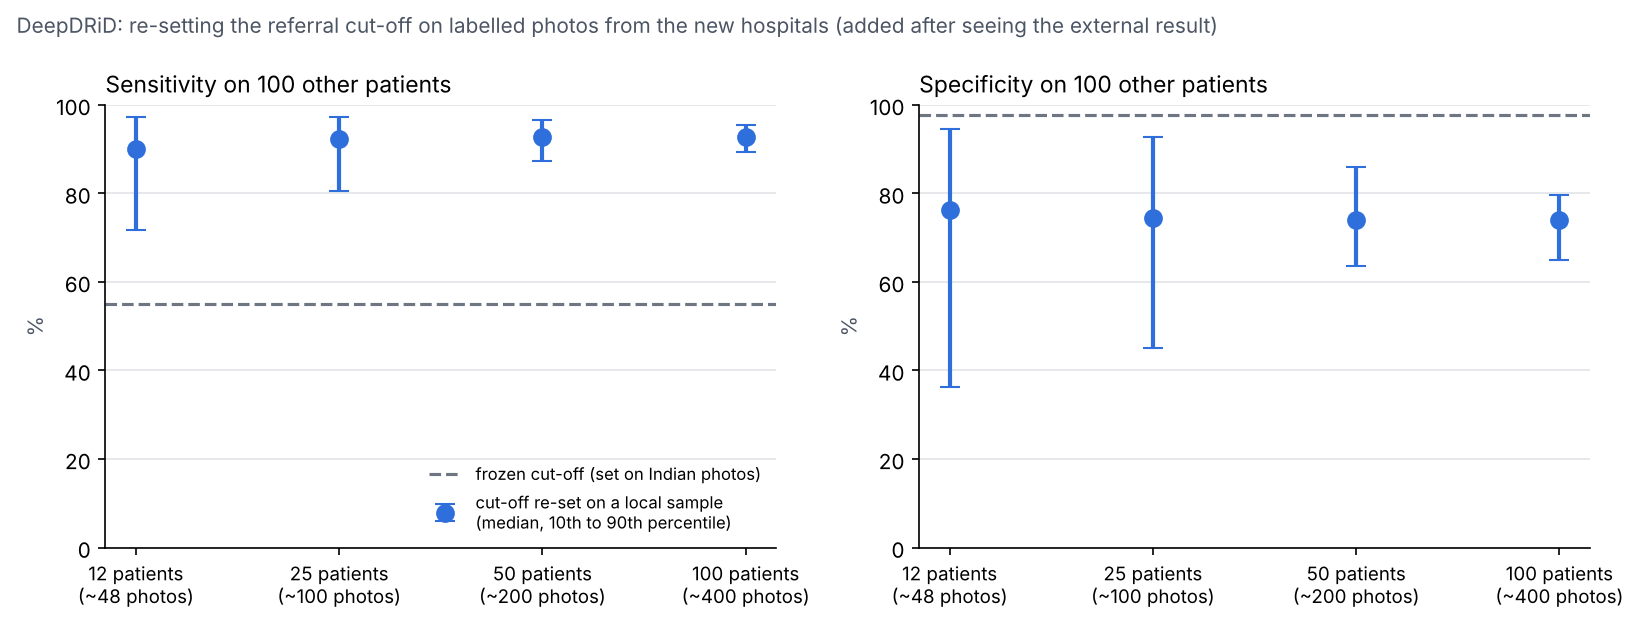

In [10]:
import local_calibration
lc = local_calibration.run('results', draws=500)
rows_lc = [dict(clinic_sample=f"{s['patients']} patients (~{s['photos_median']} photos)",
                sensitivity=f"{s['sensitivity']['median']:.1%} ({s['sensitivity']['p10']:.1%} to {s['sensitivity']['p90']:.1%})",
                specificity=f"{s['specificity']['median']:.1%} ({s['specificity']['p10']:.1%} to {s['specificity']['p90']:.1%})",
                referable_all_clears=int(s['referable_given_all_clear']['median']), referrals=int(s['REFER']['median'])) for s in lc['samples']]
f = lc['frozen']
rows_lc.insert(0, dict(clinic_sample='frozen cut-off (Indian photos)', sensitivity=f"{f['sensitivity']:.1%}", specificity=f"{f['specificity']:.1%}",
                       referable_all_clears=f['referable_given_all_clear'], referrals=f['REFER']))
display(pd.DataFrame(rows_lc))
display(Show('results/local_calibration.png', width=900))

## 4. The trained model, live, on the five demo photos
These DeepDRiD validation photos are bundled with the browser demo (`web/examples`). Each goes through exactly the clinic path: open, crop, resize, score, quality check, decide. The saved scores from the Kaggle run are shown for comparison; small differences come from GPU vs CPU arithmetic.

In [11]:
torch.set_num_threads(max(1, os.cpu_count() or 1))
model = ds.build_model(fr['arch'], pretrained=False)
model.load_state_dict(torch.load('results/model_best.pt', map_location='cpu')); model.eval()
import warnings
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    gate = pickle.load(open('results/quality_gate.pkl', 'rb'))
vers = {(w.message.original_sklearn_version, w.message.current_sklearn_version) for w in caught if hasattr(w.message, 'original_sklearn_version')}
for old, now in vers:
        print(f'Note: the quality check was saved with scikit-learn {old} on Kaggle and is loaded here '
              f'with {now}; section 6 shows it still reproduces the saved scores.')
cfg = json.load(open('web/roshni_web.json'))
saved = pd.read_csv('results/deepdrid_predictions.csv').set_index('image_id')
rows, times = [], []
for ex in cfg['examples']:
    f = os.path.join('web', ex['file']); iid = os.path.basename(f)[:-4]
    t = time.perf_counter(); dec, pr, pp, P, _ = ds.triage_one(model, gate, f, SIZE, THR, PT); times.append(time.perf_counter() - t)
    rows.append(dict(photo=iid, experts=ex['caption'], decision=dec, referable_score=round(pr, 3), saved_score=round(saved.loc[iid, 'p_referable'], 3),
                     poor_photo_score=round(pp, 3), saved_poor=round(saved.loc[iid, 'p_poor'], 3), saved_decision=saved.loc[iid, 'decision']))
live = pd.DataFrame(rows); display(live)
print('Same decision as the saved run:', (live.decision == live.saved_decision).sum(), 'of', len(live))
print(f'CPU time per photo here: median {np.median(times):.2f} s')

Note: the quality check was saved with scikit-learn 1.6.1 on Kaggle and is loaded here with 1.9.1; section 6 shows it still reproduces the saved scores.


,photo,experts,decision,referable_score,saved_score,poor_photo_score,saved_poor,saved_decision
0,267_r2,"Expert grade 3 (Severe), photo quality good",REFER,0.958,0.957,0.180,0.175,REFER
1,306_l2,"Expert grade 4 (Proliferative), photo quality ...",REFER,0.927,0.927,1.000,1.000,REFER
2,322_r1,"Expert grade 0 (No DR), photo quality poor",RETAKE,0.165,0.165,1.000,1.000,RETAKE
3,410_l1,"Expert grade 0 (No DR), photo quality good",RESCREEN,0.034,0.035,0.001,0.001,RESCREEN
4,381_l2,"Expert grade 2 (Moderate), photo quality good....",RESCREEN,0.021,0.021,0.013,0.013,RESCREEN


Same decision as the saved run: 5 of 5
CPU time per photo here: median 0.05 s


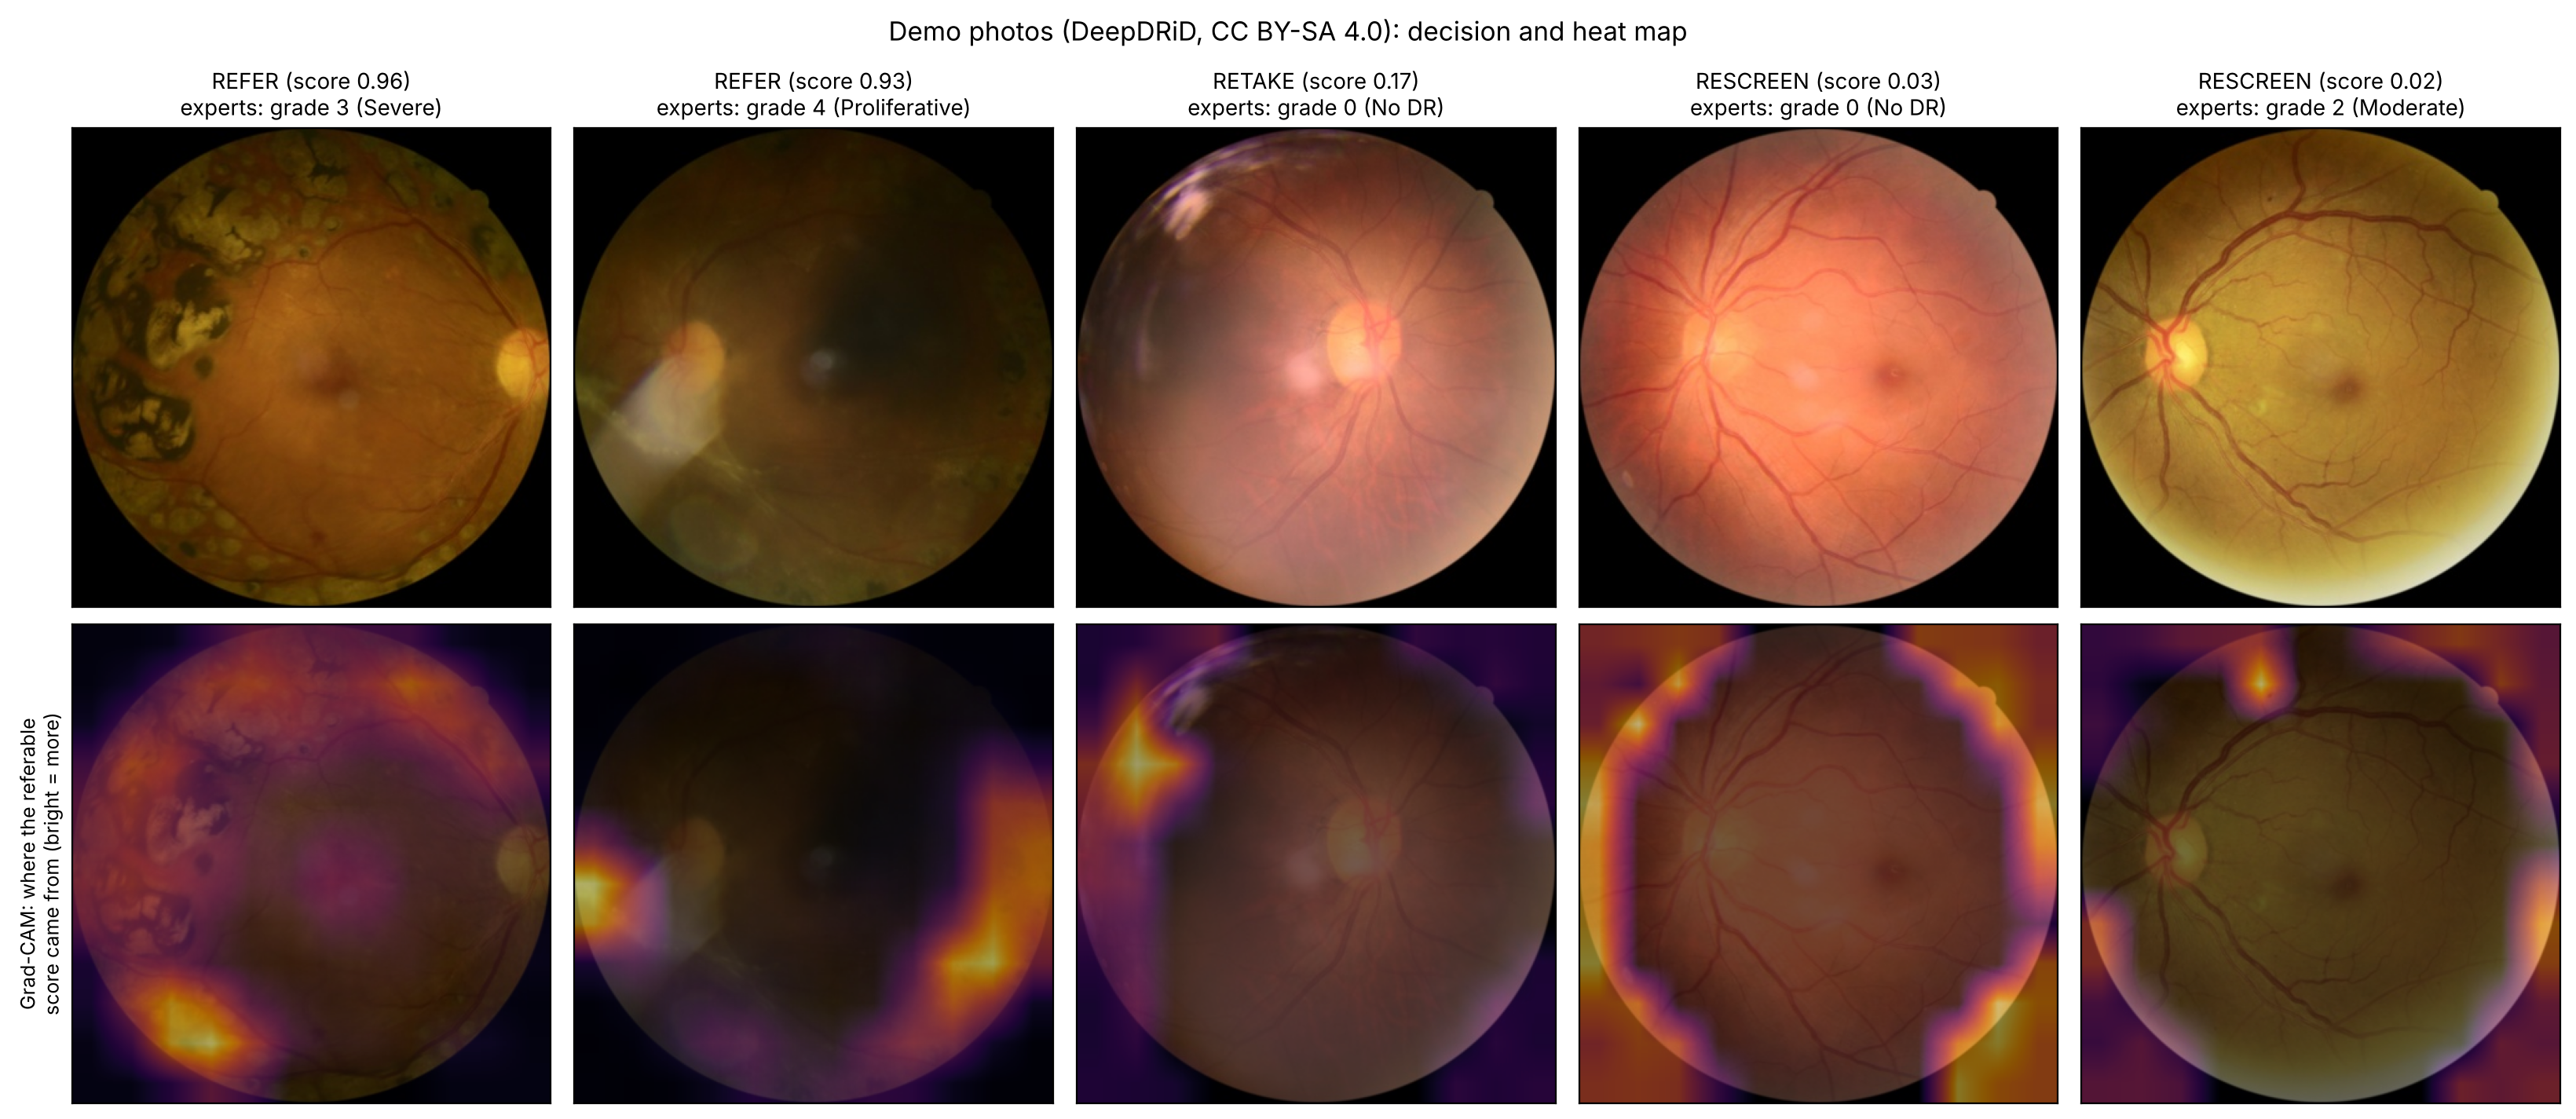

In [12]:
from PIL import Image as PILImage
fig, axes = plt.subplots(2, len(cfg['examples']), figsize=(3.3 * len(cfg['examples']), 7.4))
for i, (ex, r) in enumerate(zip(cfg['examples'], rows)):
    f = os.path.join('web', ex['file']); base = ds.prep_image(f, SIZE)
    cam = np.asarray(PILImage.fromarray(np.uint8(ds.gradcam_map(model, f, SIZE, device='cpu') * 255)).resize((SIZE, SIZE), PILImage.BILINEAR)) / 255
    grade = ex['caption'].split(', photo')[0].replace('Expert grade', 'experts: grade')
    axes[0, i].imshow(base); axes[0, i].set_title(f"{r['decision']} (score {r['referable_score']:.2f})\n{grade}", fontsize=10)
    axes[1, i].imshow(base); axes[1, i].imshow(cam, cmap='inferno', alpha=0.55)
    for a in axes[:, i]: a.set_xticks([]); a.set_yticks([])
axes[1, 0].set_ylabel('Grad-CAM: where the referable\nscore came from (bright = more)', fontsize=9)
fig.suptitle('Demo photos (DeepDRiD, CC BY-SA 4.0): decision and heat map', fontsize=12); plt.tight_layout(); plt.show()

**How to read the heat maps, honestly.** Grad-CAM is computed on the network's last 12 x 12 grid, so it is coarse, and it is rescaled per photo, so for a low score (the two RESCREEN photos) it only shows where the small score came from and means little. On several photos it lights up the edge of the field of view rather than lesions. We show it as a hint for the doctor, not as an explanation, and we have not checked it against lesion annotations.

### The note the clinic gets (English and Urdu)

In [13]:
display(HTML(ds.slip_html(rows[0]['decision'])))
print('Languages shown:', [ds.LANGS[c]['name'] + ('' if ds.LANGS[c]['checked'] else ' (translation being checked)') for c in ds.shown_langs()])

Languages shown: ['English', 'اردو (translation being checked)']


## 5. The browser model gives the same numbers as PyTorch
`web/model.onnx` is what runs in the browser demo. Here it is run with ONNX Runtime on the same inputs.

In [14]:
try:
    import onnxruntime as ort
    sess = ort.InferenceSession('web/model.onnx', providers=['CPUExecutionProvider'])
    tf = ds.get_transforms(SIZE, False); worst = 0.0
    for ex in cfg['examples']:
        x = tf(ds.prep_image(os.path.join('web', ex['file']), SIZE)).unsqueeze(0)
        with torch.no_grad(): ref = model(x).numpy()
        out = sess.run(None, {sess.get_inputs()[0].name: x.numpy()})[0]
        worst = max(worst, float(np.abs(out - ref).max()))
    print(f'Largest difference in the model outputs, ONNX vs PyTorch, over {len(cfg["examples"])} photos: {worst:.2e}')
except ImportError:
    print('pip install onnxruntime to run this check')

Largest difference in the model outputs, ONNX vs PyTorch, over 5 photos: 1.17e-04


## 6. Optional: re-score all 400 external validation photos
Needs the DeepDRiD photos (CC BY-SA 4.0). Set `DDR_ROOT` to a local copy, or set `DOWNLOAD_DEEPDRID=1` to clone https://github.com/deepdrdoc/DeepDRiD (a large download). About 3 to 5 minutes on a laptop CPU.

In [15]:
root = os.environ.get('DDR_ROOT') or ('DeepDRiD' if os.path.isdir('DeepDRiD') else None)
if root is None and os.environ.get('DOWNLOAD_DEEPDRID') == '1':
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/deepdrdoc/DeepDRiD.git'], check=True); root = 'DeepDRiD'
if root is None:
    print('Skipped: DeepDRiD photos not available here.')
else:
    srcs = [os.path.join(root, p.split('DeepDRiD/', 1)[1]) for p in v.path]
    t = time.time()
    cached = ds.cache_images(srcs, 'cache/ddr_check', size=SIZE, workers=2)
    P, E = ds.predict(model, ds.make_dataset(cached, v.grade.tolist(), SIZE, train=False), batch_size=16, device='cpu', workers=0, with_embeddings=True)
    pr, pp = ds.referable_prob(P), gate.predict_proba(E)[:, 1]
    dec = np.asarray(ds.decide(pr, pp, THR, PT))
    print(f'{len(v)} photos in {time.time() - t:.0f} s')
    print('Referable score vs saved run: median difference', f'{np.median(np.abs(pr - v.p_referable.values)):.1e}',
          '| largest', f'{np.abs(pr - v.p_referable.values).max():.1e}')
    print('Same decision as the saved run:', int((dec == v.decision.values).sum()), 'of', len(v))
    diff = v.assign(now=dec, now_ref=pr.round(3), now_poor=pp.round(3))[dec != v.decision.values]
    if len(diff): print('Different (each sits next to a cut-off; small numeric differences between the Kaggle GPU run and this CPU decide it):'); display(diff[['image_id', 'decision', 'now', 'p_referable', 'now_ref', 'p_poor', 'now_poor']].round(3))

Cached 400 images to cache/ddr_check in 12s; 0 failed


400 photos in 43 s
Referable score vs saved run: median difference 3.2e-04 | largest 9.0e-03
Same decision as the saved run: 399 of 400
Different (each sits next to a cut-off; small numeric differences between the Kaggle GPU run and this CPU decide it):


,image_id,decision,now,p_referable,now_ref,p_poor,now_poor
1238,303_r1,RESCREEN,RETAKE,0.568,0.568,0.485,0.505


## 7. v2: more cameras in training (pre-registered)
`PREREGISTRATION_v2.md` was committed to GitHub before v2 was trained. Here the five pre-set tests are recomputed from v2's per-photo predictions in `results_v2/`, not taken from its summary file.

In [16]:
if os.path.exists('results_v2/results.json'):
    r2 = json.load(open('results_v2/results.json')); T2, P2 = r2['frozen']['ref_threshold'], r2['frozen']['poor_threshold']
    d2 = pd.read_csv('results_v2/deepdrid_predictions.csv'); g2 = d2[d2.grade <= 4]
    y2, p2 = (g2.grade >= 2).values, (g2.p_referable >= T2).values
    sens2, spec2 = (p2 & y2).sum() / y2.sum(), (~p2 & ~y2).sum() / (~y2).sum()
    v2v = g2[g2.part == 'validation']
    dec2 = np.where(v2v.p_referable >= T2, 'REFER', np.where(v2v.p_poor >= P2, 'RETAKE', 'RESCREEN'))
    fac2 = int(((dec2 == 'RESCREEN') & (v2v.grade >= 2)).sum())
    a2 = pd.read_csv('results_v2/aptos_test_predictions.csv'); auc2 = roc_auc_score(a2.grade >= 2, a2.p_referable)
    nc2 = int(d2.near_copy_in_training.sum())
    tests = [('DeepDRiD sensitivity >= 66.1%', f'{sens2:.1%}', sens2 >= 0.661), ('DeepDRiD specificity >= 85.0%', f'{spec2:.1%}', spec2 >= 0.85),
             ('APTOS test AUC >= 0.950', f'{auc2:.3f}', auc2 >= 0.95), ('false all-clears (400-photo workflow) <= 46', str(fac2), fac2 <= 46),
             ('fewer than 16 DeepDRiD near-copies in the added photos', str(nc2), nc2 < 16)]
    display(pd.DataFrame(tests, columns=['pre-registered test', 'v2', 'passed']))
    print('Verdict:', 'v2 replaces v1' if all(t[2] for t in tests) else 'v1 stays the demo model; v2 is reported in full')
    print(f'For comparison, v1 on the same DeepDRiD photos: sensitivity {res["results"]["external_all"]["sensitivity"]:.1%}, '
          f'specificity {res["results"]["external_all"]["specificity"]:.1%}')
else:
    print('results_v2/ not found')

,pre-registered test,v2,passed
0,DeepDRiD sensitivity >= 66.1%,94.9%,True
1,DeepDRiD specificity >= 85.0%,78.2%,False
2,APTOS test AUC >= 0.950,0.975,True
3,false all-clears (400-photo workflow) <= 46,3,True
4,fewer than 16 DeepDRiD near-copies in the adde...,81,False


Verdict: v1 stays the demo model; v2 is reported in full
For comparison, v1 on the same DeepDRiD photos: sensitivity 56.1%, specificity 97.2%


## Where it fails
Referable eyes given an all-clear on the external photos (lowest scores first). Our reading of them is in the README's Results section.

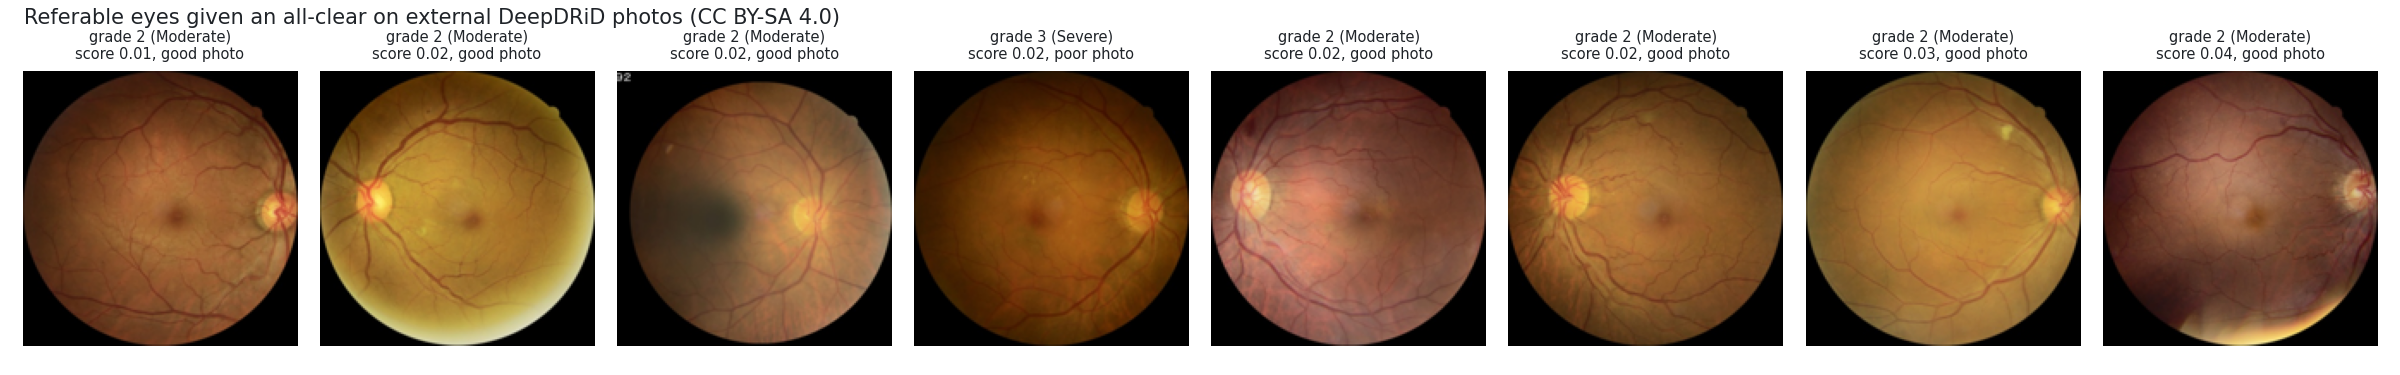

In [17]:
display(Show('results/missed_external.png', width=1000))